# **1. pyanote**

### 1. 화자 분리
화자 분리는 긴 녹음 파일을 듣고 언제 누가 말했는지를 시간 구간으로 나누는 작업

```
0.0 ~ 2.4초 "안녕하세요. 회의를 시작하겠습니다." SPEAKER_00
2.8 ~ 5.0초 "네, 자료를 준비했습니다." SPEAKDF01
5.8 ~ 7.2초 "첫번 째 안건부터 보겠습니다." SPEAKER_00
8.0 ~ 10.1초 "자료 너무 좋은 것 같습니다." SPEAKER_01
```

> SPEAKR_00은 실명이나 사용자 ID가 아님. 같은 녹음에서 같은 사람이라고 판단한 구간에 붙인 임시 라벨

- ASR: 음성 인식
- VAD: 음성 활동 탐지. 음성 / 비음성 구간
- 화자 분리: 화자별 시간 구간
- 화자 식별: 별도의 등록 음성/인증 체계 필요 > 이 보이스는 등록된 XXX인가?

### 2. 컴퓨터가 사람의 목소리를 구별하는 방법
- 사람도 전화 통화에서 얼굴을 보지 않고 상대를 구별
- 말투, 발음 습관, 성대 / 발성 특성, 음색과 억양 등이 다르기 때문
- AI는 이런 특징을 학습한 신경망으로 음성을 숫자 벡터(화자 임베딩)으로 바꿈

### 처리 순서
1. 오디오 읽기: wav를 샘플 값으로 읽음. 16kHz 모노라면 1초에 샘플 16,000개
2. 음성 구간 분석 / 분할: 짧은 시간 창마다 발화 여부와 여러 화자가 활동하는지 추정. 무음과 발화 경계가 중요
3. 화자 임베딩: 각 발화 구간의 목소리 특성을 고정 길이 숫자 벡터로 표현. 문장 뜻보다는 화자 구별에 유용한 음향적 특징을 학습
4. 화자 군집화: 비슷한 임베딩을 묶어 동일한 화자로 판단. 서로 다른 구간이 멀리 떨어져 있어도 같은 화자로 연결할 수 있음
5. 시간축 재구성: 군집 결과를 원래 발화 시간에 다시 매핑하고 SPEAKER_00 같은 라벨을 부여


### 겹쳐 말하는 상황
- 두 사람이 4.0 ~ 4.5초에 동시에 말하면 일반 화자 분리 결과는 두 화자의 구간이 겹칠 수 있음
- exclusive_speaker_diarization은 같은 시간에 하나의 화자만 배정하도록 만든 결과 > ASR 전사 결과 > 실제 동시 발화를 업앤 것처럼 복원

```
강의실에서 수강생 A와 B가 번갈아 발표하는 상황
- 음성 구간 탐지: "지금 누가 말하고 있음"
- 특징 추출: "이 구간은 작고 거친 음색, 다음 구간은 밝은 음색"
- 군집화: "첫 번째와  세 번째 발화가 비슷하므로 SPEAKER_00
- 시간 정보 결합: "A는 0~2초, B는 3~5초, A는 6~8초"
```

> 목소리 높낮이 만으로 판단하지 않음. 한 사람이 소리를 높이거나 속삭여도 같은 화자일 수 있고, 다른 두 사람의 목소리가 비슷할 수도 있음. 따라서 임베딩은 여러 음향 특징을 함께 학습

> 짧은 대답, 웃음, 배경 음악이 있는 경우, 마이크 변경, 겹침, 멀리서 말하는 소리 등은 구분할 정보가 부족하거나 달라져서 오류가 생길 수 있음

In [1]:
import soundfile as sf
import librosa
import numpy as np
import os
import random
import torch

from pathlib import Path
from dotenv import load_dotenv
from pyannote.audio import Pipeline

c:\harwoon\14_Agent\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
AUDIO_PATH = Path("meeting.wav")
PREPARED_PATH = Path("meeting_16k_mono.wav") # 전처리 후 새로 저장할 경로
TARGET_SR = 16000

wave, original_sr = sf.read(AUDIO_PATH, dtype="float32")
print("원본 샘플링 레이트: ", original_sr, "원본 shape: ",wave.shape)

원본 샘플링 레이트:  16000 원본 shape:  (480000,)


In [3]:
if wave.ndim == 2:
    wave = wave.mean(axis=1)

if original_sr != TARGET_SR:
    wave = librosa.resample(wave, orig_sr=original_sr, target_sr=TARGET_SR)

sf.write(PREPARED_PATH, wave, TARGET_SR)
print(f"변환 완료: {PREPARED_PATH} / {len(wave) / TARGET_SR:.2f}초")

변환 완료: meeting_16k_mono.wav / 30.00초


In [4]:
load_dotenv()

True

In [5]:
HF_TOKEN = os.getenv("HF_TOKEN")
if not HF_TOKEN:
    raise ValueError("HF_TOKEN ERROR!")

In [ ]:
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cpu


In [8]:
pipeline = Pipeline.from_pretrained("pyannote/speaker-diarization-community-1", token=HF_TOKEN)
pipeline.to(DEVICE)

c:\harwoon\14_Agent\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\dorot\.cache\huggingface\hub\models--pyannote--speaker-diarization-community-1. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


In [9]:
output = pipeline(str(PREPARED_PATH)) # 정확히 2명일 때 num_speakers=2 설정
for segement, speaker in output.speaker_diarization:
    print(f"{segement.start:6.2f} ~ {segement.end:6.2f} | {speaker}")

RuntimeError: Could not load libtorchcodec. Likely causes:
          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, 8, and 9, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.15.0+cpu) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 9:
Traceback (most recent ca

In [11]:
# 오디오 파일 읽기
wave, sr = sf.read(PREPARED_PATH, dtype="float32")

# NumPy → PyTorch Tensor
waveform = torch.from_numpy(wave)

# (샘플 수,) → (1, 샘플 수)
waveform = waveform.unsqueeze(0)

# 오디오 데이터 직접 전달
audio = {
    "waveform": waveform,
    "sample_rate": sr
}

# 화자 분리 실행
output = pipeline(audio)

In [12]:
for segment, speaker in output.speaker_diarization:
    print(f"{segment.start:6.2f} ~ {segment.end:6.2f} | {speaker}")

  6.73 ~   6.75 | SPEAKER_00
  6.75 ~   7.03 | SPEAKER_01
  7.03 ~   7.19 | SPEAKER_00
  7.59 ~   7.61 | SPEAKER_00
  7.61 ~   8.32 | SPEAKER_01
  8.32 ~   9.92 | SPEAKER_00
  9.92 ~  10.98 | SPEAKER_01
 10.46 ~  14.75 | SPEAKER_00
 14.31 ~  17.88 | SPEAKER_01
 18.02 ~  21.51 | SPEAKER_00
 18.15 ~  18.44 | SPEAKER_01
 21.77 ~  28.50 | SPEAKER_01
 27.86 ~  29.97 | SPEAKER_00


### 일반 화자 분리 vs Exclusive 화자 분리
- 두 결과 모두 누가 언제 말했는지는 알려주지만, 여러 화자가 동시에 말하는 구간은 어떻게 표현하는지의 차이가 있음
- 일반 화자 분리: 실제 대화에서 여러 화자가 동시에 발화하는 구간을 표현할 수 있음
    - A: 0초부터 5초까지 발화, B: 3초부터 7초까지 발화 (3~5초 구간에서는 A와 B가 동시에 말하고 있음)
- Exclusive 화자 분리: 하나의 시간 구간에 최대 한 명의 화자만 배정하도록 만든 결과
    - A: 0초부터 5초까지 발화, B: 3초부터 7초까지 발화 > 실제로는 3~5초 구간에는 두 사람이 동시에 말했지만 Exclusive 결과에서는 한 번의 한 명의 화자만 표현
        - {'start':0.0, 'end':4.0, 'speaker':'SPEAKER_00}, {'start':4.0,'end':7.0, 'speaker':'SPEAKER_00'} > 중춥 발화 정보 손실

In [34]:
def to_rows(annotation):
    return[
        {"start":seg.start, "end":seg.end, "speaker":speaker} for seg, speaker in annotation
    ]

In [35]:
regular_rows = to_rows(output.speaker_diarization)
exclusive_rows = to_rows(output.exclusive_speaker_diarization)
print("일반 분리: ", regular_rows[:10])
print("Exclusive: ", exclusive_rows[:10]) # 겹치는 부분 제외인데 현재 겹치는 부분이 잘 없어 큰 차이 없음

일반 분리:  [{'start': 6.730343750000001, 'end': 6.74721875, 'speaker': 'SPEAKER_00'}, {'start': 6.74721875, 'end': 7.03409375, 'speaker': 'SPEAKER_01'}, {'start': 7.03409375, 'end': 7.185968750000001, 'speaker': 'SPEAKER_00'}, {'start': 7.59096875, 'end': 7.607843750000001, 'speaker': 'SPEAKER_00'}, {'start': 7.607843750000001, 'end': 8.316593750000003, 'speaker': 'SPEAKER_01'}, {'start': 8.316593750000003, 'end': 9.919718750000001, 'speaker': 'SPEAKER_00'}, {'start': 9.919718750000001, 'end': 10.98284375, 'speaker': 'SPEAKER_01'}, {'start': 10.45971875, 'end': 14.745968750000003, 'speaker': 'SPEAKER_00'}, {'start': 14.30721875, 'end': 17.88471875, 'speaker': 'SPEAKER_01'}, {'start': 18.01971875, 'end': 21.512843750000002, 'speaker': 'SPEAKER_00'}]
Exclusive:  [{'start': 6.730343750000001, 'end': 6.74721875, 'speaker': 'SPEAKER_00'}, {'start': 6.74721875, 'end': 7.03409375, 'speaker': 'SPEAKER_01'}, {'start': 7.03409375, 'end': 7.185968750000001, 'speaker': 'SPEAKER_00'}, {'start': 7.5909

# **2. 참가자별로 목소리 등록 회의록** 

In [30]:
import sounddevice as sd

from pyannote.audio import Model,Inference
from qwen_asr import Qwen3ASRModel

SR = 16000
MIN_RMS = 0.0008

In [21]:
# 사람의 목소리를 숫자 벡터로 변환하여 서로 같은 사람인지 비교할 수 있도록 해줌
embedding_model = Model.from_pretrained("pyannote/embedding", token=HF_TOKEN)
embedding_model.to(DEVICE)
# 불러온 임베딩 모델을 실제 음성 데이터에 적용하기 위한 추론 객체를 생성
# window = "whole": 음성을 어떤 단위로 처리할 것인지 설정. whole은 입력으로 전달된 전체 음성 구간을 하나의 단위로 처리
embedder = Inference(embedding_model, window="whole")

ASR_MODEL_ID = "Qwen/Qwen3-ASR-1.7B"
asr_dtype = (torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16) if torch.cuda.is_available() else torch.float32

# 음성에 포함된 말을 텍스트로 변환
asr_model = Qwen3ASRModel.from_pretrained(
    ASR_MODEL_ID, dtype=asr_dtype, device_map="cuda" if torch.cuda.is_available() else "cpu", max_inference_batch_size=1, max_new_tokens=256
)

c:\harwoon\14_Agent\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\dorot\.cache\huggingface\hub\models--pyannote--embedding. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\harwoon\14_Agent\.venv\Lib\site-packages\lightning\pytorch\utilities\migration\utils.py:197: Redirecting import of pytorc

### 1. 화자 등록

In [ ]:
def record_voice(seconds=12):
    print(f"{seconds}초 녹음 중... 자연스럽게 말하세요")
    recording = sd.rec(int(SR * seconds), samplerate=SR, channels=1, dtype="float32")
    sd.wait()
    return recording[:, 0].copy()

def embedding_of(wave):
    wave = np.asanyarray(wave,dtype=np.float32).reshape(-1)
    if len(wave) < SR:
        raise ValueError("화자 식별에는 최소 1초 이상의 음성이 필요합니다.")
    tensor = torch.from_numpy(wave).unsqueeze(0)
    with torch.inference_mode():
        vector = np.asanyarray(embedder({"waveform":tensor, "sample_rate":SR})).reshape(-1)
    norm = np.linalg.norm(vector)
    if norm < 1e-10:
        raise ValueError('유효한 화자 특징을 추출하지 못했습니다')
    return vector / norm

registered = {}

def enroll(name, seconds=12):
    name = name.strip()
    if not name:
        raise ValueError("이름을 입력하세요")
    audio = record_voice(seconds)
    rms = float(np.sqrt(np.mean(audio.astype(np.float64)**2)))
    if rms < MIN_RMS:
        raise ValueError(f"녹음 음량이 너무 작습니다. 다시 등록하세요")
    registered[name] = embedding_of(audio)
    print(f"등록 완료: {name} (RMS={rms:.4f})")

In [31]:
enroll("김사과")

12초 녹음 중... 자연스럽게 말하세요
등록 완료: 김사과 (RMS=0.0084)


In [32]:
enroll("오렌지")

12초 녹음 중... 자연스럽게 말하세요
등록 완료: 오렌지 (RMS=0.0079)


In [33]:
print("현재 등록된 참석자: ", list(registered))

현재 등록된 참석자:  ['김사과', '오렌지']


### 출력 예시
```
[11:49:01] 김사과: 오늘 회의를 시작하겠습니다.
[11:49:11] 오렌지: 네, 첫 번째 안건을 말씀드리겠습니다.
[11:50:03] 김사과: 예산안을 다시 검토해보세요.
```

### 2. 화자 분리와 화자 식별
- 화자 분리: 녹음에서 "언제 누가 말했는지"를 시간 구간으로 나누는 작업
- 컴퓨터는 말투, 발성, 음색을 신경망으로 고정 길이 숫자 벡터(화자 임베딩)로 바꿈 > 문장 뜻보다 누구인지 가르는 특징을 담음
    - 오디오를 읽고 16kHz 모노로 맞춤
    - 짧은 창마다 발화인지, 여러 사람이 겹치는지 봄(무음과 발화의 경계가 중요 > 음성 활동 탐지(VAD))
    - 발화 구간마다 임베딩을 만듦
    - 비슷한 임베딩을 묶어 같은 화자로 봄
    - 묶음 결과를 시간축에 다시 올려 SPEAKER_00 같은 라벨을 붙임
- 일반 화자 분리는 두 사람이 동시에 말한 겹침을 그대로 둘 수 있음. Exclusive 화자 분리는 한 시각에 화자를 한 명만 남김(ASR에 넘기기 쉽지만, 실제 겹침이 사라진 것처럼 보임)
- 화자 식별: "이 목소리가 등록된 누구인가"라는 참가자 음성을 임베딩을 저장하고 비교


In [2]:
import os
import numpy as np
import sounddevice as sd
import torch
import random
import threading
import queue

from dotenv import load_dotenv
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command
from qwen_asr import Qwen3ASRModel
from pyannote.audio import Inference, Model, Pipeline
from datetime import datetime, timedelta
from typing import TypedDict, Literal

c:\harwoon\14_Agent\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cpu


In [4]:
load_dotenv()
HF_TOKEN = os.getenv("HF_TOKEN")
if not HF_TOKEN:
    raise ValueError("HF_TOKEN Error!")

In [5]:
SR = 16000 # 16kHZ 모노. 1초 = 16,000 샘플
MIN_RMS = 0.0008 # 이 값보다 RMS가 작으면 말이 없는 구간으로 보고 전사하지 않음
PAUSE_SECONDS = 0.6 # 말이 이 시간만큼 끊기면 한 구간으로 넘김. 더 길어지면 말 중간이라도 넘길 수 있음
MAX_CHUNK = 12.0
MATCH_THRESHOLD = 0.60 # 정규화 임베딩의 내적(코사인 유사도)이 이 값보다 늦으면 등록된 사람으로 보지 않음

In [6]:
embedding_model = Model.from_pretrained("pyannote/embedding", token=HF_TOKEN)
embedding_model.to(DEVICE)
embedder = Inference(embedding_model, window="whole") # 음성 전체를 넘기기

c:\harwoon\14_Agent\.venv\Lib\site-packages\lightning\pytorch\utilities\migration\utils.py:197: Redirecting import of pytorch_lightning.callbacks.early_stopping.EarlyStopping to lightning.pytorch.callbacks.early_stopping.EarlyStopping
c:\harwoon\14_Agent\.venv\Lib\site-packages\lightning\pytorch\utilities\migration\utils.py:197: Redirecting import of pytorch_lightning.callbacks.model_checkpoint.ModelCheckpoint to lightning.pytorch.callbacks.model_checkpoint.ModelCheckpoint
c:\harwoon\14_Agent\.venv\Lib\site-packages\lightning\pytorch\utilities\migration\migration.py:208: You have multiple `ModelCheckpoint` callback states in this checkpoint, but we found state keys that would end up colliding with each other after an upgrade, which means we can't differentiate which of your checkpoint callbacks needs which states. At least one of your `ModelCheckpoint` callbacks will not be able to reload the state.
INFO: Lightning automatically upgraded your loaded checkpoint from v1.2.7 to v2.6.6. To

In [7]:
# 화자 분리 파이프라인
# 파이프라인 객체 생성
diarization = Pipeline.from_pretrained("pyannote/speaker-diarization-community-1", token=HF_TOKEN)
diarization.to(DEVICE)

ASR_MODEL_ID = "Qwen/Qwen3-ASR-1.7B"
asr_dtype = (torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16) if torch.cuda.is_available() else torch.float32

asr_model = Qwen3ASRModel.from_pretrained(
    ASR_MODEL_ID, dtype=asr_dtype, device_map="cuda" if torch.cuda.is_available() else "cpu", max_inference_batch_size=1, max_new_tokens=256
)

Loading checkpoint shards: 100%|██████████| 2/2 [00:24<00:00, 12.16s/it]
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


### 3.목소리 등록과 목소리 타자기

In [8]:
def record_voice(seconds=12,prompt=True):
    if prompt:
        print(f"{seconds}초 녹음 중... 자연스럽게 말하세요.")
    recording = sd.rec(int(SR*seconds), samplerate=SR, channels=1, dtype='float32')
    sd.wait()
    return recording[:,0].copy()

def embedding_of(wave):
    wave = np.asanyarray(wave, dtype=np.float32).reshape(-1)
    if len(wave) < SR:
        raise ValueError("화자 식별에는 최소 1초 이상의 음성이 필요합니다.")
    # (샘플 수,) > (1, 샘플 수). pyannote는 (채널, 시간) 형태로 넣어야 함
    tensor = torch.from_numpy(wave).unsqueeze(0)
    with torch.inference_mode():
        vector = np.asarray(
            embedder({"waveform":tensor, "sample_rate":SR})
        ).reshape(-1)
    norm = np.linalg.norm(vector)
    if norm < 1e-10:
        raise ValueError("유효한 화자 특징을 추출하지 못했습니다")
    return vector / norm

registered = {}

def enroll(name, seconds=12):
    name = name.strip()
    if not name:
        raise ValueError("이름을 입력하세요")
    audio = record_voice(seconds)
    rms = float(np.sqrt(np.mean(audio.astype(np.float64)**2)))
    if rms < MIN_RMS:
        raise ValueError("녹음 음량이 너무 작습니다. 다시 등록하세요")
    registered[name] = embedding_of(audio)
    print(f"등록 완료: {name} (RMS={rms:.4f})")

def match_speeker(vector):
    if not registered:
        raise ValueError("등록된 참석자가 없습니다.")
    scores = {name: float(np.dot(reference, vector)) for name, reference in registered.items()}
    best = max(scores, key=scores.get)
    if scores[best] < MATCH_THRESHOLD:
        return "미등록"
    return best


In [9]:
enroll('김사과')

12초 녹음 중... 자연스럽게 말하세요.
등록 완료: 김사과 (RMS=0.0062)


In [19]:
enroll('오렌지')

12초 녹음 중... 자연스럽게 말하세요.
등록 완료: 오렌지 (RMS=0.0049)


In [20]:
print('현재 등록된 참석자: ', list(registered))

현재 등록된 참석자:  ['김사과', '오렌지']


### 4. 회의 Supervisor
- 마이크 스레드는 그래프와 따로 돌게 만듦
- 감독자는 큐에서 받은 구간을 보고 다음 담당자를 고름
- 담당자는 자기 필드만 채운 뒤 감독자에게 돌아옴

```
담당자
capture: 말이 끊겨 큐에 들어온 구간을 꺼냄. 마이크는 멈추지 않음
diarize: 화자 분리로 발화 시각을 나눔
identify: 화자별 임베딩을 등록 음성과 비교. 임계값 미만은 미등록
asr: 현재 발화를 한국어 텍스트로 바꿈
report: "[시:분:초] 이름: 문장"을 출력하고 다음 발화로 넘어감
```

In [10]:
class MeetingMic:
    def __init__(self):
        self._parts = []                    # 수집된 음성 블록 저장
        self._samples = 0                    # 현재까지 누적된 전체 샘플 개수
        self._silent_samples = 0            # 연속적으로 감지된 무음 샘플 개수
        self._heard = False                 # 현재 구간에서 발화로 간주되는 소리가 감지되었는지 여부
        self._lock = threading.Lock()       # 여러 스레드의 동시 접근 방지
        self._ready = queue.Queue()         # 처리가 온료된 음성 구간 저장
        self._stream = sd.InputStream(      # 마이크 입력 스트림 객체
            samplerate=SR,
            channels=1,
            dtype="float32",
            blocksize=int(SR*0.1),
            callback=self._on_audio         # 음성 블록이 준비될 때 실행할 함수
        )

    def _reset(self, keep_tail=False):
        if keep_tail and self._parts:
            tail = np.concatenate(self._parts)[-int(0.3 * SR):] # 말 시작할 때 이전 말의 뒷부분을 다음 앞에 붙임
            self._parts = [tail] if len(tail) else []
            self._silent_samples = int(len(tail))
        else:
            # 현재까지 수집된 음성과 관련 상태를 모두 초기화
            # 주로 하나의 음성 구간이 완성되어 Queue에 전달할 때 사용
            self._parts = []
            self._samples = 0
        self._silent_samples = 0
        self._heard = False

    # indata: 마이크에서 수집된 실제 음성 데이터
    # frames: 전달된 오디오 프레임 개수
    # time_info: 오디오 입력과 콜백 실행에 관련된 시간 정보
    # status: 입력 오버플로 등의 스트림 상태 정보
    # 해당 매개변수들은 직접 전달하는 것이 아니라, sounddevice가 콜백 함수를 호출할 때 자동으로 전달됨
    def _on_audio(self, indata, frames, time_info, status):
        block = indata[:, 0].copy()
        rms = float(np.sqrt(np.mean(block.astype(np.float64)**2)))
        item = None
        with self._lock:
            self._parts.append(block)
            self._samples += len(block)
            if rms < MIN_RMS:
                self._silent_samples += len(block)
            else:
                self._silent_samples = 0
                self._heard = True
            dur = self._samples / SR
            if not self._heard:
                if dur >= 2.0:
                    self._reset(keep_tail=True)
                return

            # 최소 버터 길이를 충족하고 일정 시간 이상 연속 무음이 발생
            cut_for_pause = dur >= 1.0 and self._silent_samples / SR >= PAUSE_SECONDS
            # 최대 음성 버퍼 길이에 도달
            cut_for_len = dur >= MAX_CHUNK
            # 두 조건 모두 만족하지 않으면 아직 음성 구간이 완성되지 않았다고 판단하여 현재 레
            if not(cut_for_pause or cut_for_len):
                return
            audio = np.concatenate(self._parts)
            # 현재 시각에서 녹음된 음성의 길이만큼 빼서 해당 음성 구간의 시작 시각을 계산
            started = datetime.now() - timedelta(seconds=len(audio) / SR)
            # 끝부분의 무음 제거
            if cut_for_pause and not cut_for_len:
                # RMS 기반 무음 판단은 완벽하지 않기 때문에 발화의 마지막 음절이나 작은 소리가 잘릴 수 있음 > 이를 완화하기 위해 여유 구간을 남겨듐
                # 마지막 연속 무음만 제거
                keep = max(int(0.3 * SR), len(audio) - self._silent_samples + int(0.15 * SR))
                audio = audio[:keep]
            self._reset()
            item = (audio, started)
        self._ready.put(item)

    def start(self):
        with self._lock:
            self._reset()
        while True:
            try:
                self._ready.get_nowait()
            except queue.Empty:
                break
        if not self._stream.active:
            self._stream.start()

    def stop(self):
        if self._stream.active:
            self._stream.stop()

    def close(self):
        self.stop()
        self._stream.close()

    def take(self):
        return self._ready.get()

if "meeting_mic" in globals():
    meeting_mic.close()

meeting_mic = MeetingMic()

In [11]:
class MeetingState(TypedDict, total=False):
    audio: np.ndarray           # 말이 끊긴 16kHz 모노 구간
    started: datetime           # 시작 시간
    rms: float                  # 구간 음량
    silent: bool                # MIN_RMS 미만이면 True
    turns: list                 # 화자 분리가 나눈 발화
    names: dict                 # 임시 라벨 > 등록 이름 또는 미등록
    turn_index: int             # 지금 처리 중인 발화
    asr_index: int              # 전사가 끝난 발화 번호
    text: str                   # 인식된 문장
    line: str                   # 화면에 찍은 회의록 한 줄

In [12]:
def supervisor(state: MeetingState) -> Command[Literal['capture', 'diarize','identify', 'asr', 'report', '__end__']]:
    if "audio" not in state:
        return Command(goto='capture')
    if state.get('silent'):
        return Command(goto=END)
    turns = state['turns']
    if not turns:
        return Command(goto=END)
    if 'names' not in state:
        return Command(goto='identify')
    idx = state.get('turn_index', 0)
    if idx >= len(turns):
        return Command(goto=END)
    if state.get("asr_index") != idx:
        return Command(goto='asr')
    return Command(goto='report')

In [ ]:
def capture(state: MeetingState) -> Command[Literal['supervisor']]: # 음성 수집
    audio, started = meeting_mic.take()
    rms = float(np.sqrt(np.mean(audio.astype(np.float64)**2)))
    return Command(
        update={'audio':audio, 'started':started, 'rms':rms, 'silent': rms < MIN_RMS}, goto='supervisor'
    )


def diarize(state: MeetingState) -> Command[Literal['supervisor']]:
    audio = np.asarray(state['audio'], dtype=np.float32)
    waveform = torch.from_numpy(audio).unsqueeze(0)
    # output: Community-1 파이프라인은 내부적으로 음성 구간 검출, 화자 특징 추출, 화자 클러스터링 등의 작업을 수행. 동일한 사람의 발화에 동일한 임시 라벨을 부여.
    output = diarization({"waveform":waveform, 'sample_rate':SR})
    # annotation: pyannote의 객체
    # itertracks: annotaion 객체에 저장된 발화 구간을 반복적으로 반환
    annotation = output.exclusive_speaker_diarization
    # yield_label=True로 지정하지 않으면 Segment와 Track만 반환(label이 없음)
    # (segment, track, label)
    # [(segment, track, label), (segment, track, label), ...]
    tracks = list(annotation.itertracks(yield_label=True))
    if not tracks:
        tracks = list(output.speaker_diarization.itertracks(yield_label=True))
    turns = []
    for turn, _, speaker in tracks:
        if turn.end - turn.start < 0.3:
            continue
        label = str(speaker)
        if turns and turns[-1]['label'] == label and turn.start - turns[-1]['end'] <= 0.4:
            turns[-1]['end'] = float(turn.end)
            continue
        turns.append({'start':float(turn.start), 'end':float(turn.end), 'label':label})
    if not turns and len(audio) < 2 * SR:
        turns = [{"start":0.0, 'end':len(audio)/SR, 'label':'SPEAKER_00'}]
    return Command(update={'turns':turns, 'turn_index':0}, goto='supervisor')


def identify(state: MeetingState) -> Command[Literal['supervisor']]:
    audio = state['audio']
    clips = {} # 화자별 음성 저장 데이터 딕셔너리
    # 화자 분리 모델이 분석한 발화 구간 정보
    # {"start":0.0, "end": 3.0, "label":"SPEAKER_00"}, {"start":3.0, "end": 7.0, "label":"SPEAKER_01"}
    for turn in state['turns']:
        a = max(0, int(turn['start']*SR))
        b = min(len(audio)), int(turn['end'])
        if b<a:
            # setdefault: 딕셔너리에 지정한 키가 존재하면 해당 키의 값을 반환하고, 키가 존재하지 않으면 기본값을 저장한 수 그 값을 반환하는 메서드
            clips.setdefault(turn['label'], []).append(audio[a:b])
    names = {}
    unknown = 0
    # label: "SPEAKER_00", parts: audio[0:48000]
    for label, parts in clips.items():
        # 음성이 너무 짧으면 화자의 특징을 충분히 추출하기 어렵기 때문에 동일한 화자의 여러 발화 구간을 결합하여 충분한 음성 데이터를 확보하기 위해
        speech = np.concatenate(parts) # 음성이 짧으면 특징 추출이 어렵기 때문에, 음성 데이터 확보를 위해 합침
        try:
            # embedding_of: 음성 데이터를 화자의 특징을 나타내는 고정된 길이의 벡터로 변환하는 함수
            # match_speaker: 사전에 등록된 화자의 임베딩과 비교하여 가장 유사한 사람을 찾는 함수
            name = match_speeker(embedding_of(speech))
        except ValueError:
            name = '미등록'
        if name == '미등록':
            unknown += 1
            name = '미등록' if unknown == 1 else f"미등록{unknown}"
        names[label] = name
    return Command(update={"names": names}, goto="supervisor")

def asr(state: MeetingState) -> Command[Literal['supervisor']]:
    idx = state.get('turn_index', 0)
    turn = state['turns'][idx]
    audio = state['audio']
    a = max(0, int(turn['start']*SR))
    b = min(len(audio)), int(turn['end'])
    clip = audio[a:b]
    rms = float(np.sqrt(np.mean(clip.astype(np.float64)**2))) if len(clip) else 0.0
    if len(clip) < int(0.2 * SR) or rms < MIN_RMS:
        text = ""
    else:
        results = asr_model.transcribe(audio=(clip, SR), language="Korean")
        text = results[0].text.strip() if results else ""
    return Command(update={'text':text, 'asr_index':idx}, goto='supervisor')

def report(state:MeetingState) -> Command[Literal['supervisor']]:
    idx = state.get('turn_index',0)
    turn = state['turns'][idx]
    text = state.get('text','').strip()
    line = ''
    if text:
        stamp = state['started'] + timedelta(seconds=turn['start'])
        line = f"[{stamp:%H:%M:%S} {state['names'].get(turn['label'], '미등록')}: {text}]"
        print(line)
    return Command(update={"line": line, "turn_index": idx + 1}, goto="supervisor")

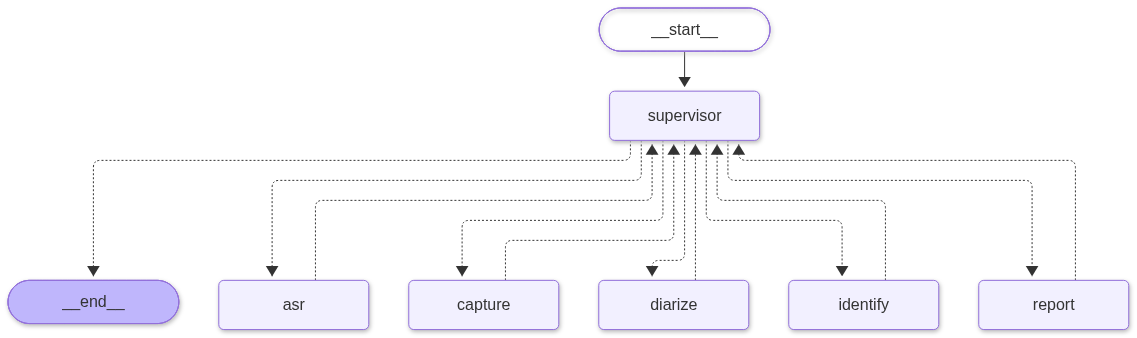

In [14]:
builder = StateGraph(MeetingState)
for name, fn in (
    ("supervisor", supervisor), ("capture", capture), ("diarize", diarize),
    ("identify", identify), ("asr", asr), ("report", report)
):
    builder.add_node(name, fn)
builder.add_edge(START, "supervisor")
meeting_graph = builder.compile()
meeting_graph

In [15]:
def start_meeting():
    if not registered:
        raise ValueError("등록된 참석자가 없습니다.")
    print("회의를 시작합니다. 종료는 인터럽트입니다.")
    print("현재 등록된 참석자: ", list(registered))
    meeting_mic.start()
    try:
        while True:
            meeting_graph.invoke({}, config={"recursion_limit": 250})
    except KeyboardInterrupt:
        print("회의를 종료합니다.")
    finally:
        meeting_mic.stop()

In [ ]:
start_meeting()

### 과제
1. 화자 등록 및 관리 기능
    - 등록된 화자 정보를 파일 또는 데이터베이스에 저장
    - 등록, 조회, 수정 및 삭제

2. 음성 구간 검출
    - 기존 RMS 기반 무음 판단 방식의 한꼐점
    - VAD 모델을 활용하여 실제 사람이 발화하는 음성 구간을 검출
    - 불필요한 무음 및 비음성 구간에 대한 모델 추론을 최소화

3. 다중 화자 분리 및 식별
    - 하나의 음성 청크에 여러 화자가 존재할 경우 화자별 발화 구간을 분리
    - 화자별 발화 시작 시간과 종료 시간을 기록

4. 음성 인식 개선
    - 고정된 단위 음성 처리 방식의 문제점을 분석하고 개선
    - 발화 중간에 문장이 끊기거나 텍스트가 중복 및 누락되는 현상을 최소

5. LLM 기반 지능형 회의록
    - 회의 전체 내용을 요약
    - 최종 결정 사항이 무엇인지

* 사용자 인터페이스를 구현